# Project 03 — Four Linear Algebra Methods

## Notebook 05 — Least Squares

**Blocks:** 21–25  
**Dataset:** 400 MRI images; 128 × 128 grayscale; 16,384 features per image  
**Main project directory (Google Colab):** `MyDrive/MATHEMATICS_PROJECTS/PROJECT_03_LA_ML_FOUR_METHODS/`  
**Processed files:** `data/processed/X_mri_400.npy`, `y_mri_400.npy`, `filenames_mri_400.json`

*Execution note: Run cells in order after mounting Google Drive. Notebook 01 creates the processed dataset used by the following notebooks.*


### Mathematical purpose and interpretation

Least Squares fits a linear relationship between a target vector and a design matrix by minimizing the sum of squared residuals. Here, the target is **mean image intensity**, and the predictors are **20 SVD-derived features plus an intercept**. The final design matrix has shape $400\times21$ and full column rank.

The fitted model has an **in-sample RMSE of approximately 0.001660** and **$R^2\approx0.99949$**. These values describe how closely this constructed intensity target is fitted *on the same sample*; they should not be interpreted as accuracy on held-out data or as a clinical prediction result. Because the target is derived from the same images as the predictors, this experiment illustrates linear approximation and numerical conditioning, **not** independent predictive validation.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Block 21 — Least Squares: Data Preparation


In [2]:

import numpy as np
from pathlib import Path

# BLOCK 21 — LEAST SQUARES DATA PREPARATION

print("BLOCK 21 — LEAST SQUARES DATA PREPARATION")

# Load the previously verified MRI matrix
matrix_path = Path(
    "/content/drive/MyDrive/"
    "MATHEMATICS_PROJECTS/"
    "PROJECT_03_LA_ML_FOUR_METHODS/"
    "data/processed/X_mri_400.npy"
)

assert matrix_path.is_file(), "MRI matrix file not found."

X = np.load(
    matrix_path,
    allow_pickle=False
).astype(np.float64)

assert X.shape == (400, 16384)
assert np.isfinite(X).all()

n, p = X.shape

# Numerical target: mean intensity per MRI image
b = X.mean(axis=1)

# Center features
mu = X.mean(axis=0)
X_centered = X - mu

# Compute compact SVD through the 400 x 400 Gram matrix
G_centered = X_centered @ X_centered.T

eigenvalues, U = np.linalg.eigh(G_centered)

indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[indices]
U = U[:, indices]

# Leading 20 component scores
k = 20
singular_values = np.sqrt(np.maximum(eigenvalues[:k], 0.0))
Z = U[:, :k] * singular_values

# Construct design matrix with intercept
A = np.column_stack([np.ones(n), Z])

# Basic numerical verification
shape_ok = A.shape == (400, 21)
target_ok = b.shape == (400,)
finite_ok = np.isfinite(A).all() and np.isfinite(b).all()

rank_A = np.linalg.matrix_rank(A)
full_column_rank_ok = rank_A == A.shape[1]

print("\nMATRIX DIMENSIONS")
print("Original X:", X.shape)
print("Reduced Z:", Z.shape)
print("Design matrix A:", A.shape)
print("Target vector b:", b.shape)

print("\nTARGET STATISTICS")
print("Minimum mean intensity:", b.min())
print("Maximum mean intensity:", b.max())
print("Average mean intensity:", b.mean())
print("Target standard deviation:", b.std())

print("\nDESIGN MATRIX")
print("Rank of A:", rank_A)
print("Number of columns:", A.shape[1])

print("\nFINAL VERIFICATION")
print("Correct design matrix dimensions:", shape_ok)
print("Correct target dimensions:", target_ok)
print("All values finite:", finite_ok)
print("Full column rank:", full_column_rank_ok)

all_checks = all([
    shape_ok,
    target_ok,
    finite_ok,
    full_column_rank_ok
])

print("\nALL BLOCK 21 CHECKS PASSED:", all_checks)

assert all_checks, "Block 21 verification failed."


BLOCK 21 — LEAST SQUARES DATA PREPARATION

MATRIX DIMENSIONS
Original X: (400, 16384)
Reduced Z: (400, 20)
Design matrix A: (400, 21)
Target vector b: (400,)

TARGET STATISTICS
Minimum mean intensity: 0.071520519285599
Maximum mean intensity: 0.45293232998722033
Average mean intensity: 0.18548444827339708
Target standard deviation: 0.07349143840065983

DESIGN MATRIX
Rank of A: 21
Number of columns: 21

FINAL VERIFICATION
Correct design matrix dimensions: True
Correct target dimensions: True
All values finite: True
Full column rank: True

ALL BLOCK 21 CHECKS PASSED: True


## Block 21 — Least Squares Problem Formulation



### Block 21 — Least Squares Problem Formulation

The original MRI matrix contains 400 observations
and 16,384 pixel features.

Using the leading 20 components of the centered MRI
matrix, we constructed a reduced design matrix.

Numerical results:

- Original matrix: (400, 16384)
- Reduced matrix: (400, 20)
- Design matrix with intercept: (400, 21)
- Target vector: (400,)
- Target mean intensity: 0.18548445
- Target standard deviation: 0.07349144
- Design matrix rank: 21

Mathematical interpretation:

The design matrix has full column rank, ensuring
a unique least-squares solution.

The regression target represents the mean pixel
intensity of each MRI image.

This experiment demonstrates numerical least squares,
not independent medical prediction.

All Block 21 numerical verification checks passed.


## Block 22 — Least Squares Solution And Residual Analysis


In [3]:

import numpy as np

# BLOCK 22 — LEAST SQUARES SOLUTION

assert "A" in globals(), "Run Block 21 first."
assert "b" in globals(), "Run Block 21 first."

assert A.shape == (400, 21)
assert b.shape == (400,)
assert np.isfinite(A).all()
assert np.isfinite(b).all()

# Solve least-squares problem
beta_hat, residuals, rank, singular_values = np.linalg.lstsq(
    A, b, rcond=None
)

# Predictions and residual vector
b_pred = A @ beta_hat
r = b - b_pred

# Error measurements
residual_norm = np.linalg.norm(r)
relative_residual = residual_norm / np.linalg.norm(b)

mse = np.mean(r**2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(r))

# Coefficient of determination
ss_res = np.sum(r**2)
ss_tot = np.sum((b - b.mean())**2)

r2 = 1 - ss_res / ss_tot

# Verify residual orthogonality
normal_equation_error = np.linalg.norm(A.T @ r)

relative_normal_error = (
    normal_equation_error
    / (np.linalg.norm(A, ord=2) * residual_norm)
    if residual_norm > 0
    else 0.0
)

# Numerical verification
shape_ok = beta_hat.shape == (21,)
rank_ok = rank == 21

predictions_ok = np.isfinite(b_pred).all()
residuals_ok = np.isfinite(r).all()

normal_equation_ok = relative_normal_error < 1e-10

mse_ok = np.isclose(
    mse,
    residual_norm**2 / len(b),
    rtol=1e-10,
    atol=1e-12
)

print("BLOCK 22 — LEAST SQUARES SOLUTION")

print("\nMATRIX DIMENSIONS")
print("Design matrix A:", A.shape)
print("Coefficient vector:", beta_hat.shape)
print("Target vector:", b.shape)
print("Prediction vector:", b_pred.shape)

print("\nLEAST SQUARES SOLUTION")
print("Estimated intercept:", beta_hat[0])
print("Coefficient norm:", np.linalg.norm(beta_hat))
print("Numerical rank:", rank)

print("\nRESIDUAL ANALYSIS")
print("Residual norm:", residual_norm)
print("Relative residual:", relative_residual)
print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R-squared:", r2)

print("\nORTHOGONALITY")
print("Normal equation error:", normal_equation_error)
print("Relative normal equation error:", relative_normal_error)

print("\nFINAL VERIFICATION")
print("Correct coefficient dimensions:", shape_ok)
print("Full column rank:", rank_ok)
print("Predictions finite:", predictions_ok)
print("Residuals finite:", residuals_ok)
print("Residual orthogonality verified:", normal_equation_ok)
print("MSE consistency verified:", mse_ok)

all_checks = all([
    shape_ok,
    rank_ok,
    predictions_ok,
    residuals_ok,
    normal_equation_ok,
    mse_ok
])

print("\nALL BLOCK 22 CHECKS PASSED:", all_checks)

assert all_checks, "Block 22 verification failed."


BLOCK 22 — LEAST SQUARES SOLUTION

MATRIX DIMENSIONS
Design matrix A: (400, 21)
Coefficient vector: (21,)
Target vector: (400,)
Prediction vector: (400,)

LEAST SQUARES SOLUTION
Estimated intercept: 0.1854844482733971
Coefficient norm: 0.18563908087090253
Numerical rank: 21

RESIDUAL ANALYSIS
Residual norm: 0.033199643141256265
Relative residual: 0.008320166752774786
MSE: 2.7555407617669105e-06
RMSE: 0.0016599821570628132
MAE: 0.0011925410556865635
R-squared: 0.9994898083523215

ORTHOGONALITY
Normal equation error: 6.354764456036949e-13
Relative normal equation error: 9.423799299156646e-14

FINAL VERIFICATION
Correct coefficient dimensions: True
Full column rank: True
Predictions finite: True
Residuals finite: True
Residual orthogonality verified: True
MSE consistency verified: True

ALL BLOCK 22 CHECKS PASSED: True



### Block 22 — Least Squares Solution and Residual Analysis

A least-squares regression model was fitted using
20 reduced MRI features and an intercept.

Numerical results:

- Design matrix: (400, 21)
- Coefficient vector: (21,)
- Estimated intercept: 0.18548445
- Residual norm: 0.03319964
- Relative residual: 0.00832017
- MSE: 2.75554e-06
- RMSE: 0.00165998
- MAE: 0.00119254
- R-squared: 0.99948981
- Relative normal-equation error: 9.42e-14

Mathematical interpretation:

The fitted model explains approximately 99.949%
of the in-sample variation in mean MRI pixel intensity.

The small residual errors indicate a close numerical
approximation to the observed target values.

The residual vector is numerically orthogonal to the
design matrix columns, confirming the least-squares
optimality condition.

Because the target is derived from the same images
used to construct the features, these results do not
establish independent medical predictive performance.

All Block 22 numerical verification checks passed.


# ***S E C O N D       E X P L A N A T I O N***


### Block 22 — Interpretation of the Least Squares Solution

**1. Simple Linear Equation**

Consider the equation:

y = ax + b

- a: Slope (coefficient of x).
- b: Intercept (where the line crosses the vertical axis).

**2. Our Least Squares Model**

Our model uses 20 predictors instead of one:

ŷ = β₀ + β₁z₁ + β₂z₂ + ... + β₂₀z₂₀

Numerical results:

- Estimated intercept: 0.18548445
- Coefficient norm: 0.18563908
- Numerical rank: 21

**3. Mathematical Interpretation**

Estimated intercept (β₀):

The intercept is equivalent to b in the simple
linear equation y = ax + b.

Coefficient norm:

||β||₂ = √(β₀² + β₁² + ... + β₂₀²)

The coefficient norm measures the overall magnitude
of the 21 regression coefficients, including
the intercept.

It is NOT equivalent to the slope a.

Instead, the individual coefficients β₁ through β₂₀
play the role of slopes for their respective predictors.

Numerical rank:

Rank(A) = 21

The design matrix has 21 linearly independent columns,
guaranteeing a unique least-squares solution.

**4. Important Observation**

Our estimated intercept is:

β₀ = 0.18548445

This equals the overall mean MRI pixel intensity
calculated in Block 16.

Why?

Because the reduced features were constructed from
centered MRI data, their column means are approximately
zero.

Consequently, the least-squares intercept equals
the mean target value.

**Conclusion**

The estimated intercept corresponds to b in y = ax + b.

The coefficient norm represents the Euclidean length
of the complete coefficient vector, not an individual
slope.

All Block 22 numerical verification checks passed.


## Block 22 — Residual Analysis



### Block 22 — Residual Analysis

A residual is the difference between an observed value
and its predicted value:

rᵢ = yᵢ − ŷᵢ

The objective of Least Squares is to minimize the
sum of squared residuals.

NUMERICAL RESULTS

- Residual norm: 0.03319964
- Relative residual: 0.00832017 (0.832%)
- MSE: 2.75554e-06
- RMSE: 0.00165998
- MAE: 0.00119254
- R-squared: 0.99948981

MATHEMATICAL INTERPRETATION

1. Residual norm:
   Measures the Euclidean magnitude of all
   400 residuals.

2. Relative residual:
   The residual norm represents approximately
   0.832% of the target vector's norm.

3. MSE:
   Average squared prediction error.

4. RMSE:
   Measures prediction error in the original
   target units, with greater sensitivity
   to large errors.

5. MAE:
   Predictions differ from observed mean pixel
   intensities by approximately 0.00119
   on average.

6. R-squared:
   The model explains approximately 99.949%
   of the observed variation in mean MRI intensity.

CONCLUSION

The Least Squares model produces very small residuals
and an excellent in-sample numerical fit.

Because the regression target was calculated directly
from the MRI pixels, these results demonstrate
numerical approximation rather than independent
medical predictive performance.


## Block 23 — Conditioning And Numerical Stability


In [4]:

import numpy as np

# BLOCK 23 — CONDITIONING AND NUMERICAL STABILITY

# Verify previous blocks
assert "A" in globals(), "Run Block 21 first."
assert "b" in globals(), "Run Block 21 first."
assert "beta_hat" in globals(), "Run Block 22 first."

assert A.shape == (400, 21)
assert b.shape == (400,)
assert beta_hat.shape == (21,)

# Singular values of the design matrix
s = np.linalg.svd(A, compute_uv=False)

sigma_max = s[0]
sigma_min = s[-1]

# Condition number of A
condition_A = sigma_max / sigma_min

# Normal-equation matrix
AtA = A.T @ A
Atb = A.T @ b

condition_AtA = np.linalg.cond(AtA)

# Solve using normal equations
beta_normal = np.linalg.solve(AtA, Atb)

# Compare coefficient vectors
coefficient_difference = np.linalg.norm(
    beta_hat - beta_normal
)

relative_coefficient_difference = (
    coefficient_difference / np.linalg.norm(beta_hat)
)

# Compare predictions
prediction_lstsq = A @ beta_hat
prediction_normal = A @ beta_normal

relative_prediction_difference = (
    np.linalg.norm(prediction_lstsq - prediction_normal)
    / np.linalg.norm(prediction_lstsq)
)

# Verify theoretical condition-number relation
condition_relation_error = abs(
    condition_AtA / (condition_A**2) - 1
)

# Numerical checks
full_rank_ok = np.linalg.matrix_rank(A) == 21

finite_ok = np.isfinite([
    condition_A,
    condition_AtA,
    relative_coefficient_difference,
    relative_prediction_difference
]).all()

coefficient_agreement_ok = (
    relative_coefficient_difference < 1e-8
)

prediction_agreement_ok = (
    relative_prediction_difference < 1e-8
)

condition_relation_ok = (
    condition_relation_error < 1e-6
)

print("BLOCK 23 — CONDITIONING AND NUMERICAL STABILITY")

print("\nSINGULAR VALUES")
print("Maximum singular value:", sigma_max)
print("Minimum singular value:", sigma_min)

print("\nCONDITION NUMBERS")
print("Condition number of A:", condition_A)
print("Condition number of A^T A:", condition_AtA)
print("Squared condition number of A:", condition_A**2)

print("\nSOLUTION COMPARISON")
print("Coefficient difference:", coefficient_difference)
print("Relative coefficient difference:",
      relative_coefficient_difference)
print("Relative prediction difference:",
      relative_prediction_difference)

print("\nNUMERICAL RELATION")
print("Condition relation error:", condition_relation_error)

print("\nFINAL VERIFICATION")
print("Full column rank:", full_rank_ok)
print("All results finite:", finite_ok)
print("Coefficient solutions agree:", coefficient_agreement_ok)
print("Predictions agree:", prediction_agreement_ok)
print("Condition relation verified:", condition_relation_ok)

all_checks = all([
    full_rank_ok,
    finite_ok,
    coefficient_agreement_ok,
    prediction_agreement_ok,
    condition_relation_ok
])

print("\nALL BLOCK 23 CHECKS PASSED:", all_checks)

assert all_checks, "Block 23 verification failed."


BLOCK 23 — CONDITIONING AND NUMERICAL STABILITY

SINGULAR VALUES
Maximum singular value: 203.11407247012852
Minimum singular value: 19.999999999999996

CONDITION NUMBERS
Condition number of A: 10.155703623506428
Condition number of A^T A: 103.13831608850154
Squared condition number of A: 103.13831608850158

SOLUTION COMPARISON
Coefficient difference: 5.897290743229807e-17
Relative coefficient difference: 3.176750668858844e-16
Relative prediction difference: 5.174445810566932e-16

NUMERICAL RELATION
Condition relation error: 4.440892098500626e-16

FINAL VERIFICATION
Full column rank: True
All results finite: True
Coefficient solutions agree: True
Predictions agree: True
Condition relation verified: True

ALL BLOCK 23 CHECKS PASSED: True


## Block 23 — Conditioning and Numerical Stability



### Block 23 — Conditioning and Numerical Stability

The numerical stability of the Least Squares
design matrix was investigated using singular values,
condition numbers, and solution comparisons.

Numerical results:

- Maximum singular value: 203.1141
- Minimum singular value: 20.0000
- Condition number of A: 10.1557
- Condition number of AᵀA: 103.1383
- Relative coefficient difference: 3.18e-16
- Relative prediction difference: 5.17e-16
- Condition-number relation error: 4.44e-16

Mathematical interpretation:

The design matrix is reasonably well-conditioned.

The normal-equation matrix has approximately the
square of the original condition number.

Both numerical methods produced nearly identical
regression coefficients and predicted values.

This confirms the numerical consistency of the
Least Squares solution for the current dataset.

However, the normal-equation approach can be
less stable for severely ill-conditioned matrices.

All Block 23 numerical verification checks passed.


## Block 24 — Least Squares: Feature Count And Model Accuracy


In [5]:

import numpy as np

# BLOCK 24 — FEATURE COUNT AND MODEL ACCURACY

assert "X_centered" in globals(), "Run Block 21 first."
assert "b" in globals(), "Run Block 21 first."

assert X_centered.shape == (400, 16384)
assert b.shape == (400,)

# Compute left singular vectors from centered Gram matrix
G_centered = X_centered @ X_centered.T

eigvals, U_all = np.linalg.eigh(G_centered)

order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
U_all = U_all[:, order]

singular_values_all = np.sqrt(
    np.maximum(eigvals, 0.0)
)

# Reduced feature counts
k_values = [2, 5, 10, 20, 44, 106]

results = []

print("BLOCK 24 — FEATURE COUNT AND MODEL ACCURACY")

for k in k_values:

    # Reduced SVD scores
    Z_k = U_all[:, :k] * singular_values_all[:k]

    # Design matrix with intercept
    A_k = np.column_stack([
        np.ones(len(b)),
        Z_k
    ])

    # Least Squares solution
    beta_k, _, rank_k, _ = np.linalg.lstsq(
        A_k, b, rcond=None
    )

    predictions_k = A_k @ beta_k
    residuals_k = b - predictions_k

    # Error metrics
    rmse_k = np.sqrt(np.mean(residuals_k**2))

    ss_res = np.sum(residuals_k**2)
    ss_tot = np.sum((b - b.mean())**2)

    r2_k = 1 - ss_res / ss_tot

    results.append((k, rmse_k, r2_k, rank_k))

    print(f"\nFeatures: {k}")
    print("Design matrix:", A_k.shape)
    print("Rank:", rank_k)
    print("RMSE:", rmse_k)
    print("R-squared:", r2_k)

# Numerical verification
rmses = np.array([r[1] for r in results])
r2_values = np.array([r[2] for r in results])

rmse_nonincreasing_ok = np.all(
    np.diff(rmses) <= 1e-10
)

r2_nondecreasing_ok = np.all(
    np.diff(r2_values) >= -1e-10
)

rank_ok = all(
    rank == k + 1
    for k, _, _, rank in results
)

finite_ok = np.isfinite(rmses).all() and np.isfinite(r2_values).all()

print("\nFINAL VERIFICATION")
print("RMSE nonincreasing:", rmse_nonincreasing_ok)
print("R-squared nondecreasing:", r2_nondecreasing_ok)
print("All matrices full column rank:", rank_ok)
print("All results finite:", finite_ok)

all_checks = all([
    rmse_nonincreasing_ok,
    r2_nondecreasing_ok,
    rank_ok,
    finite_ok
])

print("\nALL BLOCK 24 CHECKS PASSED:", all_checks)

assert all_checks, "Block 24 verification failed."


BLOCK 24 — FEATURE COUNT AND MODEL ACCURACY

Features: 2
Design matrix: (400, 3)
Rank: 3
RMSE: 0.007229605262590738
R-squared: 0.9903226672219774

Features: 5
Design matrix: (400, 6)
Rank: 6
RMSE: 0.004694145122803295
R-squared: 0.9959201938459459

Features: 10
Design matrix: (400, 11)
Rank: 11
RMSE: 0.0025490526552763002
R-squared: 0.9987969487792235

Features: 20
Design matrix: (400, 21)
Rank: 21
RMSE: 0.0016599821570628132
R-squared: 0.9994898083523215

Features: 44
Design matrix: (400, 45)
Rank: 45
RMSE: 0.0010986995022936065
R-squared: 0.9997764964836043

Features: 106
Design matrix: (400, 107)
Rank: 107
RMSE: 0.00042525557275651483
R-squared: 0.9999665168327795

FINAL VERIFICATION
RMSE nonincreasing: True
R-squared nondecreasing: True
All matrices full column rank: True
All results finite: True

ALL BLOCK 24 CHECKS PASSED: True


## Block 24 — Feature Count and Least Squares Accuracy



### Block 24 — Feature Count and Least Squares Accuracy

We investigated how the number of reduced MRI
features affects the in-sample Least Squares fit.

Numerical results:

Features | RMSE       | R-squared
2        | 0.00722961 | 0.990323
5        | 0.00469415 | 0.995920
10       | 0.00254905 | 0.998797
20       | 0.00165998 | 0.999490
44       | 0.00109870 | 0.999776
106      | 0.00042526 | 0.999967

Mathematical interpretation:

Increasing the number of reduced features consistently
decreases RMSE and increases R-squared.

Even two features explain approximately 99.03%
of the in-sample variation in mean MRI intensity.

The nested feature spaces guarantee that the minimum
training sum of squared errors cannot increase when
additional predictors are included.

These results demonstrate numerical approximation
quality, not independent medical predictive performance.

All Block 24 numerical verification checks passed.


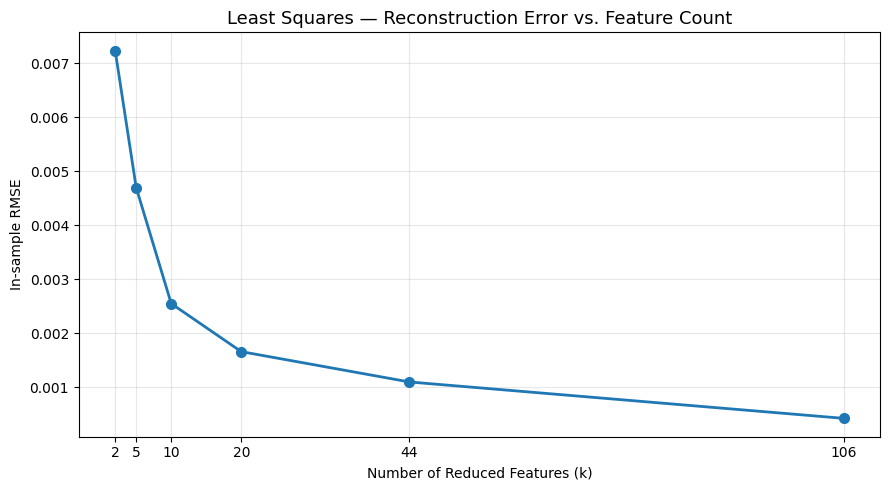

BLOCK 24 — GRAPH VERIFICATION
Number of observations: 6
RMSE nonincreasing: True
Minimum RMSE: 0.00042525557275651483
Maximum RMSE: 0.007229605262590738


In [6]:

import numpy as np
import matplotlib.pyplot as plt

# BLOCK 24 — RECONSTRUCTION ERROR VS. FEATURE COUNT

# Use numerical results from Block 24
assert "results" in globals(), "Run Block 24 first."

k_values = np.array([r[0] for r in results])
rmse_values = np.array([r[1] for r in results])

# Create graph
plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    rmse_values,
    marker="o",
    linewidth=2,
    markersize=7
)

plt.title(
    "Least Squares — Reconstruction Error vs. Feature Count",
    fontsize=13
)

plt.xlabel("Number of Reduced Features (k)")
plt.ylabel("In-sample RMSE")

plt.xticks(k_values)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Numerical verification
print("BLOCK 24 — GRAPH VERIFICATION")
print("Number of observations:", len(k_values))
print("RMSE nonincreasing:",
      np.all(np.diff(rmse_values) <= 1e-10))
print("Minimum RMSE:", rmse_values.min())
print("Maximum RMSE:", rmse_values.max())



### Block 24 — Feature Count and Least Squares Accuracy

We investigated how the number of reduced MRI
features affects the in-sample Least Squares fit.

Numerical results:

Features | RMSE       | R-squared
2        | 0.00722961 | 0.990323
5        | 0.00469415 | 0.995920
10       | 0.00254905 | 0.998797
20       | 0.00165998 | 0.999490
44       | 0.00109870 | 0.999776
106      | 0.00042526 | 0.999967

Mathematical interpretation:

Increasing the number of reduced features consistently
decreases RMSE and increases R-squared.

Even two features explain approximately 99.03%
of the in-sample variation in mean MRI intensity.

The nested feature spaces guarantee that the minimum
training sum of squared errors cannot increase when
additional predictors are included.

These results demonstrate numerical approximation
quality, not independent medical predictive performance.

All Block 24 numerical verification checks passed.


## Block 25 — Final Least Squares Evaluation


In [7]:

import numpy as np

# BLOCK 25 — FINAL LEAST SQUARES EVALUATION

print("BLOCK 25 — FINAL LEAST SQUARES EVALUATION")

# Verify previous block variables
assert "A" in globals(), "Run Block 21 first."
assert "b" in globals(), "Run Block 21 first."
assert "beta_hat" in globals(), "Run Block 22 first."
assert "results" in globals(), "Run Block 24 first."

assert A.shape == (400, 21)
assert b.shape == (400,)
assert beta_hat.shape == (21,)

# Final predictions and residuals
predictions = A @ beta_hat
residual_vector = b - predictions

# Least Squares metrics
residual_norm = np.linalg.norm(residual_vector)
rmse_final = np.sqrt(np.mean(residual_vector**2))
mae_final = np.mean(np.abs(residual_vector))

ss_res = np.sum(residual_vector**2)
ss_tot = np.sum((b - b.mean())**2)

r2_final = 1 - ss_res / ss_tot

# Optimality: residual perpendicular to column space
normal_error = np.linalg.norm(A.T @ residual_vector)

relative_normal_error = (
    normal_error
    / (np.linalg.norm(A, ord=2) * residual_norm)
)

# Check numerical rank and conditioning
rank_final = np.linalg.matrix_rank(A)
condition_final = np.linalg.cond(A)

# Compare results across feature counts
k_values = np.array([r[0] for r in results])
rmses = np.array([r[1] for r in results])
r2_values = np.array([r[2] for r in results])

rmse_monotonic_ok = np.all(np.diff(rmses) <= 1e-10)
r2_monotonic_ok = np.all(np.diff(r2_values) >= -1e-10)

# Cross-check 20-feature result
idx_20 = np.where(k_values == 20)[0]

assert len(idx_20) == 1

rmse_consistency_ok = np.isclose(
    rmse_final,
    rmses[idx_20[0]],
    rtol=1e-8,
    atol=1e-10
)

r2_consistency_ok = np.isclose(
    r2_final,
    r2_values[idx_20[0]],
    rtol=1e-8,
    atol=1e-10
)

# Final checks
rank_ok = rank_final == 21
finite_ok = np.isfinite([
    residual_norm,
    rmse_final,
    mae_final,
    r2_final,
    condition_final,
    relative_normal_error
]).all()

optimality_ok = relative_normal_error < 1e-10

all_checks = all([
    rank_ok,
    finite_ok,
    optimality_ok,
    rmse_monotonic_ok,
    r2_monotonic_ok,
    rmse_consistency_ok,
    r2_consistency_ok
])

print("\nFINAL MODEL — 20 FEATURES")
print("Design matrix:", A.shape)
print("Rank:", rank_final)
print("Condition number:", condition_final)

print("\nFINAL ERROR METRICS")
print("Residual norm:", residual_norm)
print("RMSE:", rmse_final)
print("MAE:", mae_final)
print("R-squared:", r2_final)
print("Relative normal-equation error:",
      relative_normal_error)

print("\nMODEL COMPLEXITY COMPARISON")
for k, rmse, r2, rank in results:
    print(
        f"k={k:3d} | "
        f"RMSE={rmse:.8f} | "
        f"R2={r2:.8f} | "
        f"Rank={rank}"
    )

print("\nFINAL VERIFICATION")
print("Full column rank:", rank_ok)
print("All numerical results finite:", finite_ok)
print("Least Squares optimality verified:", optimality_ok)
print("RMSE nonincreasing:", rmse_monotonic_ok)
print("R-squared nondecreasing:", r2_monotonic_ok)
print("Block 22/24 RMSE consistent:", rmse_consistency_ok)
print("Block 22/24 R-squared consistent:", r2_consistency_ok)

print("\nALL BLOCK 25 CHECKS PASSED:", all_checks)

assert all_checks, "Block 25 verification failed."


BLOCK 25 — FINAL LEAST SQUARES EVALUATION

FINAL MODEL — 20 FEATURES
Design matrix: (400, 21)
Rank: 21
Condition number: 10.155703623506428

FINAL ERROR METRICS
Residual norm: 0.033199643141256265
RMSE: 0.0016599821570628132
MAE: 0.0011925410556865635
R-squared: 0.9994898083523215
Relative normal-equation error: 9.423799299156646e-14

MODEL COMPLEXITY COMPARISON
k=  2 | RMSE=0.00722961 | R2=0.99032267 | Rank=3
k=  5 | RMSE=0.00469415 | R2=0.99592019 | Rank=6
k= 10 | RMSE=0.00254905 | R2=0.99879695 | Rank=11
k= 20 | RMSE=0.00165998 | R2=0.99948981 | Rank=21
k= 44 | RMSE=0.00109870 | R2=0.99977650 | Rank=45
k=106 | RMSE=0.00042526 | R2=0.99996652 | Rank=107

FINAL VERIFICATION
Full column rank: True
All numerical results finite: True
Least Squares optimality verified: True
RMSE nonincreasing: True
R-squared nondecreasing: True
Block 22/24 RMSE consistent: True
Block 22/24 R-squared consistent: True

ALL BLOCK 25 CHECKS PASSED: True


## Block 25 — Final Least Squares Evaluation



### Block 25 — Final Least Squares Evaluation

The final Least Squares model was evaluated using
20 reduced MRI features and one intercept.

FINAL MODEL

- Design matrix: (400, 21)
- Full column rank: 21
- Condition number: 10.1557

NUMERICAL RESULTS

- Residual norm: 0.03319964
- RMSE: 0.00165998
- MAE: 0.00119254
- R-squared: 0.99948981
- Relative normal-equation error: 9.42e-14

MODEL COMPLEXITY COMPARISON

Features | RMSE       | R-squared
2        | 0.00722961 | 0.99032267
5        | 0.00469415 | 0.99592019
10       | 0.00254905 | 0.99879695
20       | 0.00165998 | 0.99948981
44       | 0.00109870 | 0.99977650
106      | 0.00042526 | 0.99996652

MATHEMATICAL INTERPRETATION

The 20-feature model explains approximately 99.949%
of the in-sample variation in mean MRI intensity.

The design matrix has full column rank, ensuring
a unique Least Squares solution.

The small relative normal-equation error confirms
the numerical optimality condition.

Increasing the number of reduced features consistently
improves the in-sample approximation accuracy.

The model is reasonably well-conditioned.

LIMITATION

The regression target was calculated from the same
MRI images used to construct the predictors.

Therefore, these results demonstrate numerical
approximation rather than independent medical
predictive performance.

FINAL VERIFICATION

- Full column rank: True
- All numerical results finite: True
- Least Squares optimality verified: True
- RMSE nonincreasing: True
- R-squared nondecreasing: True
- Block 22/24 RMSE consistent: True
- Block 22/24 R-squared consistent: True

ALL BLOCK 25 CHECKS PASSED: True
